In [1]:
speaker_info = open('/mnt/nvme-data1/waris/datasets/LibriTTS_O/speakers.tsv', 'r').readlines()

speaker2gender = {}
for line in speaker_info[1:]:
    sprkid, gender = line.strip().split('\t')[:2]
    speaker2gender[sprkid] = gender

In [2]:
import glob

files = glob.glob('/mnt/nvme-data1/waris/streamVC_data/data/**/wav/*.wav')
print(len(files))

354780


In [3]:
import random
random.seed(1234)

random.shuffle(files)

In [4]:
from pathlib import Path

filtered_files = []
male_count = 0
female_count = 0
for file in files:
    if male_count > len(files)//10 and female_count > len(files)//10:
        break

    spkr = Path(file).parent.parent.name
    if spkr in speaker2gender:
        if speaker2gender[spkr] == 'M' and male_count <= len(files)//10:
            filtered_files.append((file, 'M'))
            male_count += 1
        if speaker2gender[spkr] == 'F' and female_count <= len(files)//10:
            filtered_files.append((file, 'F'))
            female_count += 1

In [5]:
len(filtered_files)

70958

In [6]:
from pathlib import Path
import numpy as np
import torch
import librosa
import soundfile
from speechbrain.inference import EncoderClassifier

_xvec_model = None # type: EncoderClassifier
_tdnn_model = None # type: EncoderClassifier
_device = None # type: torch.device


def load_model(device=None):
    """
    Loads the model in memory. If this function is not explicitely called, it will be run on the 
    first call to embed_frames() with the default weights file.
    
    :param weights_fpath: the path to saved model weights.
    :param device: either a torch device or the name of a torch device (e.g. "cpu", "cuda"). The 
    model will be loaded and will run on this device. Outputs will however always be on the cpu. 
    If None, will default to your GPU if it"s available, otherwise your CPU.
    """
    # TODO: I think the slow loading of the encoder might have something to do with the device it
    #   was saved on. Worth investigating.
    global _xvec_model, _tdnn_model, _device
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
        _device = torch.device(device)
    elif isinstance(device, str):
        _device = torch.device(device)
        
    _tdnn_model = EncoderClassifier.from_hparams(source='speechbrain/spkrec-ecapa-voxceleb',
                                                 savedir='pretrained_models/speaker/spkrec-ecapa-voxceleb',
                                                 run_opts={'device': device})
    _xvec_model = EncoderClassifier.from_hparams(source='speechbrain/spkrec-xvect-voxceleb',
                                                 savedir='pretrained_models/speaker/spkrec-xvect-voxceleb',
                                                 run_opts={'device': device})
    _tdnn_model.eval()
    _xvec_model.eval()
    print("Loaded Speaker encoder.")


def is_loaded():
    return _tdnn_model is not None and _xvec_model is not None

@torch.no_grad()
def generate_speaker_embedding(wav_file, sample_rate:int=16000):
    """
    Args:
        wav_file: Path to audio wav file
        sample_rate: target sample rate
    
    returns:
        1D Speaker Embed vector (H,)
    """
    wave, _ = librosa.load(wav_file, sr=sample_rate)
    wave = torch.tensor(np.trim_zeros(wave))

    spk_emb_x = _xvec_model.encode_batch(wavs=wave.unsqueeze(0)).squeeze()
    spk_emb_t = _tdnn_model.encode_batch(wavs=wave.unsqueeze(0)).squeeze()
    embed = torch.cat([spk_emb_x, spk_emb_t], dim=0)
    
    embed = embed.cpu().numpy()
    return embed

def generate_speaker_embedding_torch_batched(wave):
    spk_emb_x = _xvec_model.encode_batch(wavs=wave)
    spk_emb_t = _tdnn_model.encode_batch(wavs=wave)
    embed = torch.cat([spk_emb_x, spk_emb_t], dim=-1)

    return embed

/home/grads/q/quamer.waris/anaconda3/envs/spkrattr/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
load_model('cuda')

/home/grads/q/quamer.waris/anaconda3/envs/spkrattr/lib/python3.10/site-packages/speechbrain/utils/autocast.py:68: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  wrapped_fwd = torch.cuda.amp.custom_fwd(fwd, cast_inputs=cast_inputs)
/home/grads/q/quamer.waris/anaconda3/envs/spkrattr/lib/python3.10/site-packages/speechbrain/utils/checkpoints.py:194: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded v

Loaded Speaker encoder.


In [9]:
import typing
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from transformers import Wav2Vec2Processor
from transformers.models.wav2vec2.modeling_wav2vec2 import Wav2Vec2Model
from transformers.models.wav2vec2.modeling_wav2vec2 import Wav2Vec2PreTrainedModel

import audiofile
import audresample


# device = 'cuda' if torch.cuda.is_available() else "cpu"
duration = 3  # limit processing of audio
age_gender_model_name = "audeering/wav2vec2-large-robust-24-ft-age-gender"
expression_model_name = "audeering/wav2vec2-large-robust-12-ft-emotion-msp-dim"
_age_gender_processor = None 
_age_gender_model = None
_expression_processor = None
_expression_model = None
_device = None # type: torch.device

class AgeGenderHead(nn.Module):
    r"""Age-gender model head."""

    def __init__(self, config, num_labels):

        super().__init__()

        self.dense = nn.Linear(config.hidden_size, config.hidden_size)
        self.dropout = nn.Dropout(config.final_dropout)
        self.out_proj = nn.Linear(config.hidden_size, num_labels)

    def forward(self, features, **kwargs):

        x = features
        x = self.dropout(x)
        x = self.dense(x)
        x = torch.tanh(x)
        x = self.dropout(x)
        x = self.out_proj(x)

        return x


class AgeGenderModel(Wav2Vec2PreTrainedModel):
    r"""Age-gender recognition model."""

    def __init__(self, config):

        super().__init__(config)

        self.config = config
        self.wav2vec2 = Wav2Vec2Model(config)
        self.age = AgeGenderHead(config, 1)
        self.gender = AgeGenderHead(config, 3)
        self.init_weights()

    def forward(
            self,
            input_values,
    ):

        outputs = self.wav2vec2(input_values)
        hidden_states = outputs[0]
        hidden_states = torch.mean(hidden_states, dim=1)
        logits_age = self.age(hidden_states)
        logits_gender = torch.softmax(self.gender(hidden_states), dim=1)

        return hidden_states, logits_age, logits_gender


class ExpressionHead(nn.Module):
    r"""Expression model head."""

    def __init__(self, config):

        super().__init__()

        self.dense = nn.Linear(config.hidden_size, config.hidden_size)
        self.dropout = nn.Dropout(config.final_dropout)
        self.out_proj = nn.Linear(config.hidden_size, config.num_labels)

    def forward(self, features, **kwargs):

        x = features
        x = self.dropout(x)
        x = self.dense(x)
        x = torch.tanh(x)
        x = self.dropout(x)
        x = self.out_proj(x)

        return x


class ExpressionModel(Wav2Vec2PreTrainedModel):
    r"""speech expression model."""

    def __init__(self, config):

        super().__init__(config)

        self.config = config
        self.wav2vec2 = Wav2Vec2Model(config)
        self.classifier = ExpressionHead(config)
        self.init_weights()

    def forward(self, input_values):
        outputs = self.wav2vec2(input_values)
        hidden_states = outputs[0]
        hidden_states = torch.mean(hidden_states, dim=1)
        logits = self.classifier(hidden_states)

        return hidden_states, logits


def load_models_recognize(device=None):
    global _age_gender_processor, _age_gender_model, _expression_processor, _expression_model, _device
    # Load models from hub
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
        _device = torch.device(device)
    elif isinstance(device, str):
        _device = torch.device(device)

    _age_gender_processor = Wav2Vec2Processor.from_pretrained(age_gender_model_name)
    _age_gender_model = AgeGenderModel.from_pretrained(age_gender_model_name).to(_device)
    _expression_processor = Wav2Vec2Processor.from_pretrained(expression_model_name)
    _expression_model = ExpressionModel.from_pretrained(expression_model_name).to(_device)

    print("Loaded attributes models.")


def process_func(x: np.ndarray, sampling_rate: int) -> typing.Tuple[str, dict, str]:
    r"""Predict age and gender or extract embeddings from raw audio signal."""
    # run through processor to normalize signal
    # always returns a batch, so we just get the first entry
    # then we put it on the device
    results = []
    for processor, model in zip(
            [_age_gender_processor, _expression_processor],
            [_age_gender_model, _expression_model],
    ):
        y = processor(x, sampling_rate=sampling_rate)
        y = y['input_values'][0]
        y = y.reshape(1, -1)
        y = torch.from_numpy(y).to(_device)

        # run through model
        with torch.no_grad():
            y = model(y)
            if len(y) == 3:
                # Age-gender model
                y = torch.hstack([y[1], y[2]])
            else:
                # Expression model
                y = y[1]

        # convert to numpy
        y = y.detach().cpu().numpy()
        results.append(y[0])

    return (
        results[0][0],
        {
            "female": results[0][1],
            "male": results[0][2],
            "child": results[0][3],
        },
        # expression_file,
        {
            "arousal": results[1][0], 
            "dominance": results[1][1], 
            "valence": results[1][2]
        }
    )


@torch.no_grad()
def recognize(input_file: str) -> typing.Tuple[float, dict, dict]:
    # sampling_rate, signal = input_microphone
    # signal = signal.astype(np.float32, order="C") / 32768.0
    # if input_file is None:
    #     raise gr.Error(
    #         "No audio file submitted! "
    #         "Please upload or record an audio file "
    #         "before submitting your request."
    #     )

    signal, sampling_rate = audiofile.read(input_file, duration=duration)
    # Resample to sampling rate supported byu the models
    target_rate = 16000
    if sampling_rate != target_rate:
        signal = audresample.resample(signal, sampling_rate, target_rate)

    return process_func(signal, target_rate)

In [10]:
load_models_recognize(device='cuda')

/home/grads/q/quamer.waris/anaconda3/envs/spkrattr/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1617: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be deprecated in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Loaded attributes models.


In [11]:
from tqdm import tqdm

X = []
gender = []
ages = []

for (file, label) in tqdm(filtered_files):
    embed = generate_speaker_embedding(file)
    X.append(embed)

    age, gen, expression = recognize(file)
    gender.append(gen['female'])
    ages.append(age)

100%|██████████| 70958/70958 [58:38<00:00, 20.16it/s] 


In [12]:
import pickle

dict_to_save = {
    'latents' : X,
    'gender' : gender,
    'age': ages
}

with open('/mnt/nvme-data1/waris/CortexCraft/SpeakerAttribute/data/libri_embed_gen_age.pkl', 'wb') as f:
    pickle.dump(dict_to_save, f)

In [1]:
import pickle

with open('/mnt/nvme-data1/waris/CortexCraft/SpeakerAttribute/data/libri_embed_gen_age.pkl', 'rb') as f:
    data = pickle.load(f)

print(data.keys())

dict_keys(['latents', 'gender', 'age'])


In [2]:
X = data['latents']
gender = data['gender']
ages = data['age']

In [3]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_mean_centered = np.array(X) - np.mean(X, axis=0)
pca = PCA(n_components=None)
pca.fit(X_mean_centered)

PCA()

In [4]:
X_pca = pca.transform(X_mean_centered)

In [5]:
from scipy.stats import pearsonr

# Correlate each principal component with the age
gender_correlations = [pearsonr(X_pca[:, i], gender)[0] for i in range(len(pca.components_))]
age_correlations = [pearsonr(X_pca[:, i], ages)[0] for i in range(len(pca.components_))]
explained_variance_ratio = pca.explained_variance_ratio_

In [6]:
for idx, i in enumerate(np.cumsum(explained_variance_ratio)):
    if i > 0.95:
        print(idx)
        break

184


In [7]:
k = idx

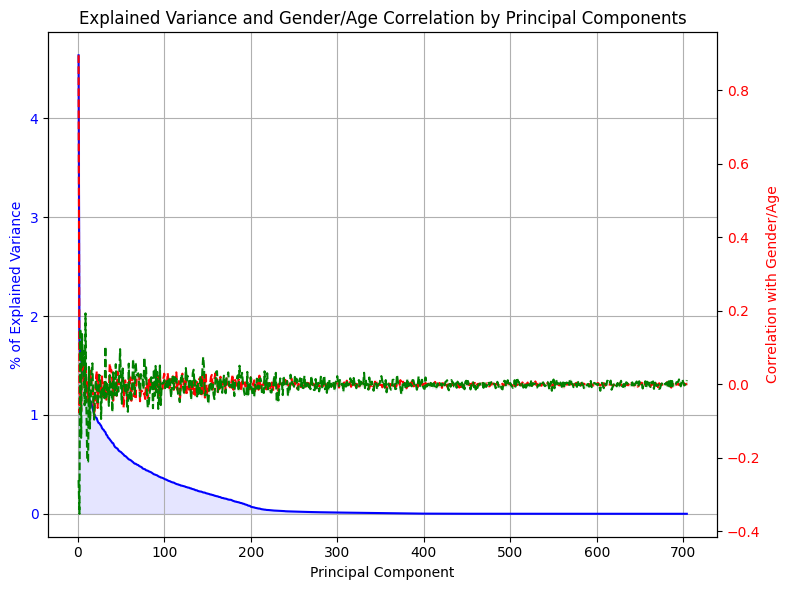

In [8]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(8, 6))

x = np.arange(1, len(explained_variance_ratio) + 1)
ax1.plot(x, explained_variance_ratio * 100, color='b', label='Explained Variance')
ax1.fill_between(x, explained_variance_ratio * 100, color='b', alpha=0.1)  # Light shadow effect

# Labels for the first y-axis (Explained Variance)
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('% of Explained Variance', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Step 5: Create the secondary y-axis for the correlation with gender
ax2 = ax1.twinx()  # Create a second axes sharing the same x-axis

# Plot correlation with gender on the secondary y-axis
ax2.plot(x, gender_correlations, color='r', label='Gender Correlation', linestyle='--')
ax2.fill_between(x, gender_correlations, color='r', alpha=0.1)  # Light shadow effect

# Plot correlation with gender on the secondary y-axis
ax2.plot(x, age_correlations, color='g', label='Age Correlation', linestyle='--')
ax2.fill_between(x, age_correlations, color='g', alpha=0.1)  # Light shadow effect

# Labels for the second y-axis (Gender Correlation)
ax2.set_ylabel('Correlation with Gender/Age', color='r')
ax2.tick_params(axis='y', labelcolor='r')


# Step 6: Add a title and show the plot
plt.title('Explained Variance and Gender/Age Correlation by Principal Components')
fig.tight_layout()  # Adjust layout to prevent overlap
plt.show()

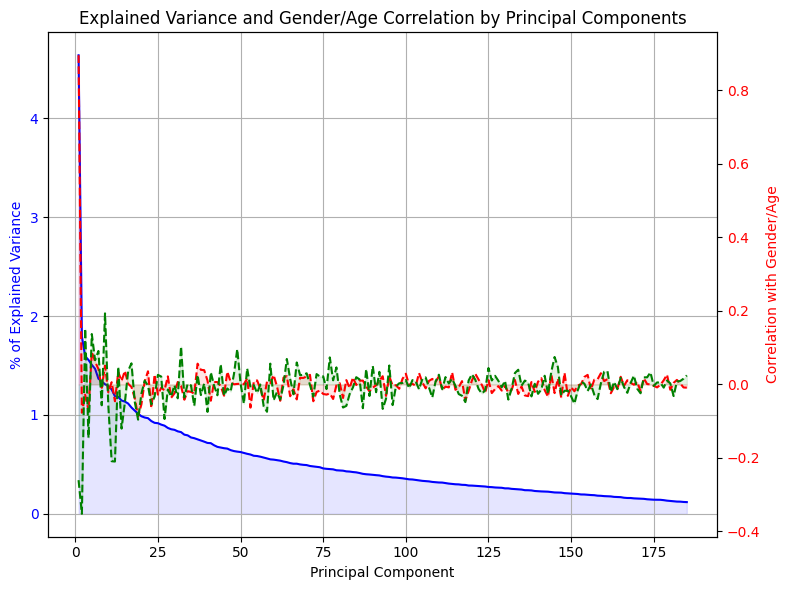

In [9]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(8, 6))

x = np.arange(1, len(explained_variance_ratio[:k+1]) + 1)
ax1.plot(x, explained_variance_ratio[:k+1] * 100, color='b', label='Explained Variance')
ax1.fill_between(x, explained_variance_ratio[:k+1] * 100, color='b', alpha=0.1)  # Light shadow effect

# Labels for the first y-axis (Explained Variance)
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('% of Explained Variance', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Step 5: Create the secondary y-axis for the correlation with gender
ax2 = ax1.twinx()  # Create a second axes sharing the same x-axis

# Plot correlation with gender on the secondary y-axis
ax2.plot(x, gender_correlations[:k+1], color='r', label='Gender Correlation', linestyle='--')
ax2.fill_between(x, gender_correlations[:k+1], color='r', alpha=0.1)  # Light shadow effect

# Plot correlation with gender on the secondary y-axis
ax2.plot(x, age_correlations[:k+1], color='g', label='Age Correlation', linestyle='--')
ax2.fill_between(x, age_correlations[:k+1], color='g', alpha=0.1)  # Light shadow effect

# Labels for the second y-axis (Gender Correlation)
ax2.set_ylabel('Correlation with Gender/Age', color='r')
ax2.tick_params(axis='y', labelcolor='r')


# Step 6: Add a title and show the plot
plt.title('Explained Variance and Gender/Age Correlation by Principal Components')
fig.tight_layout()  # Adjust layout to prevent overlap
plt.show()

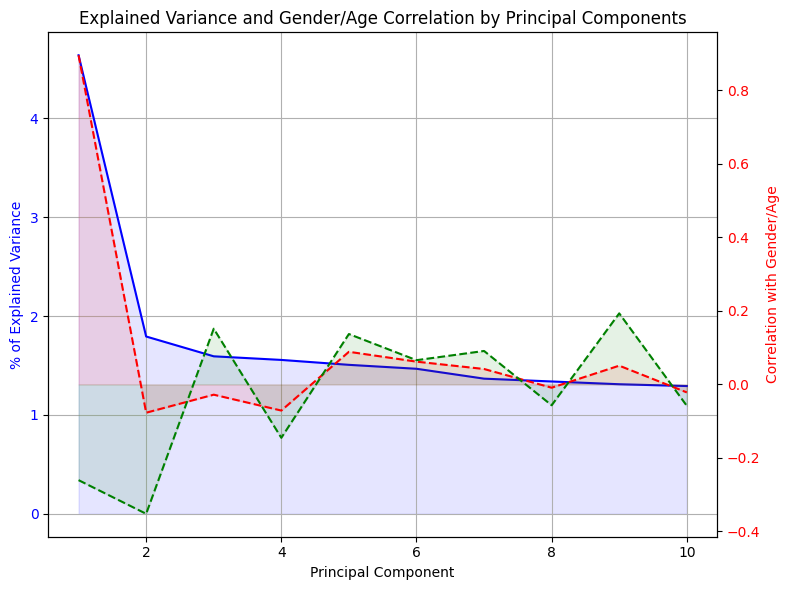

In [16]:
fig, ax1 = plt.subplots(figsize=(8, 6))

x = np.arange(1, len(explained_variance_ratio[:10]) + 1)
ax1.plot(x, explained_variance_ratio[:10] * 100, color='b', label='Explained Variance')
ax1.fill_between(x, explained_variance_ratio[:10] * 100, color='b', alpha=0.1)  # Light shadow effect

# Labels for the first y-axis (Explained Variance)
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('% of Explained Variance', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Step 5: Create the secondary y-axis for the correlation with gender
ax2 = ax1.twinx()  # Create a second axes sharing the same x-axis

# Plot correlation with gender on the secondary y-axis
ax2.plot(x, gender_correlations[:10], color='r', label='Gender Correlation', linestyle='--')
ax2.fill_between(x, gender_correlations[:10], color='r', alpha=0.1)  # Light shadow effect

# Plot correlation with gender on the secondary y-axis
ax2.plot(x, age_correlations[:10], color='g', label='Age Correlation', linestyle='--')
ax2.fill_between(x, age_correlations[:10], color='g', alpha=0.1)  # Light shadow effect

# Labels for the second y-axis (Gender Correlation)
ax2.set_ylabel('Correlation with Gender/Age', color='r')
ax2.tick_params(axis='y', labelcolor='r')

# Step 6: Add a title and show the plot
plt.title('Explained Variance and Gender/Age Correlation by Principal Components')
fig.tight_layout()  # Adjust layout to prevent overlap
plt.show()

In [41]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()

# Fit the regression model on k principal components and age
regressor.fit(X_pca[:, :k+1], gender)

LinearRegression()

In [47]:
weights = regressor.coef_
k = 185

composite_pc_gender = sum(gender_correlations[i] * pca.components_[i] for i in range(k))
composite_pc_gender_lr = sum(weights[i] * pca.components_[i] for i in range(k))

In [17]:
composite_pc_gender = sum(gender_correlations[i] * pca.components_[i] for i in range(k+1))
composite_pc_age = sum(age_correlations[i] * pca.components_[i] for i in range(k+1))

In [22]:
composite_pc_age = composite_pc_age / np.linalg.norm(composite_pc_age)

In [24]:
composite_pc_gender = composite_pc_gender / np.linalg.norm(composite_pc_gender)

In [26]:
composite_pc_dict = {
    'correlation_weight_gender': composite_pc_gender,
    'correlation_weight_age': composite_pc_age,
}

In [27]:

with open('/mnt/nvme-data1/waris/CortexCraft/SpeakerAttribute/data/composite_pc_gender_age.pkl', 'wb') as f:
    pickle.dump(composite_pc_dict, f)